# Módulo 1. Preparación del programa

En esta primera parte instalamos y cargamos las herramientas que vamos a utilizar. También conectamos Google Drive, porque allí vamos a guardar la información de cada estudiante.

In [ ]:
# Módulo 1: Preparacion del entorno

# Instalamos las librerías que vamos a usar en el proyecto

!pip install -q openai-whisper ipywidgets pandas numpy
!apt-get install -y -qq ffmpeg

from google.colab import drive, output, files
from IPython.display import display, Javascript
import csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import hashlib
import secrets
import base64
import re
import unicodedata
import whisper
from datetime import date, timedelta
from getpass import getpass

# Conectamos nuestro Google Drive

drive.mount('/content/drive')

# Creamos la carpeta donde se guardará la información

carpeta = "/content/drive/MyDrive/MoniApps"

os.makedirs(carpeta, exist_ok=True)

# Archivo para guardar las cuentas

archivo_usuarios = carpeta + "/usuarios.csv"

archivo_saldo_inicial = carpeta + "/saldo_inicial.csv"

print("MoniApps esta preparado correctamente.")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
MoniApps esta preparado correctamente.


# Módulo 2. Registro de usuario

Aquí la persona crea su cuenta para poder utilizar MoniApps. Guardamos sus datos básicos y un nombre de usuario para que pueda entrar después.

In [ ]:
# Módulo 2: Registro de usuario

def registrar_usuario():

    print("\nREGISTRO DE NUEVO USUARIO")
    print("-------------------------")

    # Consultamos los usuarios existentes

    usuarios = []

    if os.path.exists(archivo_usuarios):

        with open(archivo_usuarios, "r", encoding="utf-8") as archivo:

            lector = csv.DictReader(archivo)

            usuarios = list(lector)

    # Pedimos los datos de la persona que se va a registrar

    nombre = input("Nombre completo: ")

    edad = int(input("Edad: "))

    carrera = input("Carrera: ")

    semestre = int(input("Semestre: "))

    recibe_beca = input("¿Recibe beca? (Si/No): ")

    # Creamos el nombre de usuario

    usuario = input("Crea tu nombre de usuario: ").strip().lower()

    # Verificamos que no exista

    for persona in usuarios:

        if persona["usuario"] == usuario:

            print("Este nombre de usuario ya existe")

            return

    # Solicitamos la contraseña

    clave = getpass("Crea tu contraseña: ")

    confirmar_clave = getpass("Confirma tu contraseña: ")

    if clave != confirmar_clave:

        print("Las contraseñas no coinciden")

        return

    # Guardamos una versión protegida de la contraseña

    sal = secrets.token_hex(16)

    clave_hash = hashlib.pbkdf2_hmac(
        "sha256",
        clave.encode(),
        bytes.fromhex(sal),
        100000
    ).hex()

    # Creamos el registro del usuario

    nuevo_usuario = {
        "id_usuario": len(usuarios) + 1,
        "nombre": nombre,
        "edad": edad,
        "carrera": carrera,
        "semestre": semestre,
        "recibe_beca": recibe_beca,
        "usuario": usuario,
        "sal": sal,
        "clave_hash": clave_hash
    }

    # Guardamos la información en CSV

    campos = list(nuevo_usuario.keys())

    existe = os.path.exists(archivo_usuarios)

    with open(archivo_usuarios, "a", newline="", encoding="utf-8") as archivo:

        escritor = csv.DictWriter(archivo, fieldnames=campos)

        if not existe or os.path.getsize(archivo_usuarios) == 0:

            escritor.writeheader()

        escritor.writerow(nuevo_usuario)

    print("\n¡REGISTRO COMPLETADO!")

    print("Bienvenido a MoniApps")

# Módulo 3. Inicio de sesión

En esta parte comprobamos el nombre de usuario y la contraseña. Si los datos son correctos, el programa permite entrar al menú principal.

In [ ]:

# Módulo 3: Inicio de sesion

def iniciar_sesion():

    print("\nINICIO DE SESION")
    print("----------------")

    # Verificamos que exista el archivo de usuarios

    if not os.path.exists(archivo_usuarios):

        print("No hay usuarios registrados. Primero debes registrarte.")
        return None

    # Leemos las cuentas que ya están registradas

    with open(archivo_usuarios, "r", encoding="utf-8") as archivo:

        lector = csv.DictReader(archivo)

        usuarios = list(lector)

    # Solicitamos las credenciales

    usuario = input("Nombre de usuario: ").strip().lower()

    clave = getpass("Contraseña: ")

    # Buscamos el usuario registrado

    for persona in usuarios:

        if persona["usuario"] == usuario:

            # Recuperamos la sal y la contraseña protegida

            sal = bytes.fromhex(persona["sal"])

            clave_hash = hashlib.pbkdf2_hmac(
                "sha256",
                clave.encode(),
                sal,
                100000
            ).hex()

            # Comparamos la contraseña ingresada con la guardada

            if secrets.compare_digest(clave_hash, persona["clave_hash"]):

                print("\n¡INICIO DE SESION EXITOSO!")
                print("Bienvenido(a),", persona["nombre"])

                return persona

            else:

                print("\nContraseña incorrecta.")
                return None

    print("\nEl usuario no existe.")
    return None


# Módulo 4. Categorías de ingresos y gastos

Cada estudiante puede crear las categorías que necesita. Por ejemplo, puede tener una categoría de ingreso llamada «Apoyo familiar» y una de gasto llamada «Transporte».

In [ ]:

# Módulo 4: Configuracion de categorias

# Definimos el archivo donde guardaremos las categorias

archivo_categorias = carpeta + "/categorias.csv"

# Creamos la funcion para configurar categorias

def configurar_categorias(usuario_activo):

    # Verificamos que exista una sesion activa

    if usuario_activo is None:

        print("Primero debes iniciar sesion.")
        return

    print("\nCONFIGURACION DE CATEGORIAS")
    print("---------------------------")

    # Creamos el archivo si todavia no existe

    if not os.path.exists(archivo_categorias):

        with open(archivo_categorias, "w", newline="", encoding="utf-8") as archivo:

            campos = ["id_usuario", "tipo", "categoria"]

            escritor = csv.DictWriter(archivo, fieldnames=campos)

            escritor.writeheader()

    # Mostramos el menu de opciones

    while True:

        print("\n1. Agregar categoria de ingreso")
        print("2. Agregar categoria de gasto")
        print("3. Ver mis categorias")
        print("4. Terminar")

        opcion = input("Selecciona una opcion: ")

        # Determinamos el tipo de categoria

        if opcion == "1":
            tipo = "Ingreso"

        elif opcion == "2":
            tipo = "Gasto"

        elif opcion == "3":

            with open(archivo_categorias, "r", encoding="utf-8") as archivo:

                lector = csv.DictReader(archivo)

                categorias = list(lector)

            print("\nMIS CATEGORIAS")

            for categoria in categorias:

                if categoria["id_usuario"] == str(usuario_activo["id_usuario"]):

                    print(categoria["tipo"], "-", categoria["categoria"])

            continue

        elif opcion == "4":

            print("Configuracion finalizada.")
            break

        else:

            print("Opcion no valida.")
            continue

        # Solicitamos el nombre de la categoria

        nombre_categoria = input("Nombre de la categoria: ").strip()

        if nombre_categoria == "":
            print("Debes escribir un nombre.")
            continue

        # Leemos las categorias existentes

        with open(archivo_categorias, "r", encoding="utf-8") as archivo:

            lector = csv.DictReader(archivo)

            categorias = list(lector)

        # Verificamos que no este repetida para ese usuario y tipo

        bandera = False

        for categoria in categorias:

            if (
                categoria["id_usuario"] == str(usuario_activo["id_usuario"])
                and categoria["tipo"] == tipo
                and categoria["categoria"].lower() == nombre_categoria.lower()
            ):

                bandera = True

        if bandera:

            print("Esta categoria ya existe.")
            continue

        # Guardamos la nueva categoria

        with open(archivo_categorias, "a", newline="", encoding="utf-8") as archivo:

            campos = ["id_usuario", "tipo", "categoria"]

            escritor = csv.DictWriter(archivo, fieldnames=campos)

            escritor.writerow({
                "id_usuario": usuario_activo["id_usuario"],
                "tipo": tipo,
                "categoria": nombre_categoria
            })

        print("Categoria guardada correctamente.")


# Módulo 5. Presupuesto mensual

En este módulo se registra cuánto dinero tiene disponible el estudiante para el mes y cómo quiere repartirlo entre sus categorías de gastos.

In [ ]:

# Módulo 5: Configuracion del presupuesto

# Archivo donde guardaremos los presupuestos

archivo_presupuestos = carpeta + "/presupuestos.csv"


def configurar_presupuesto(usuario_activo):

    # Verificamos que exista una sesion activa

    if usuario_activo is None:
        print("Primero debes iniciar sesion.")
        return

    # Leemos las categorias de gasto del estudiante

    with open(archivo_categorias, "r", encoding="utf-8") as archivo:

        lector = csv.DictReader(archivo)

        categorias = [
            fila["categoria"]
            for fila in lector
            if fila["id_usuario"] == str(usuario_activo["id_usuario"])
            and fila["tipo"] == "Gasto"
        ]

    if not categorias:
        print("Primero debes crear categorias de gastos.")
        return

    print("\nCONFIGURACION DEL PRESUPUESTO MENSUAL")
    print("-------------------------------------")

    # Solicitamos el presupuesto total

    while True:

        try:

            presupuesto_mensual = int(
                input("¿Cuanto dinero tienes disponible para el mes? $")
            )

            if presupuesto_mensual > 0:
                break

            print("El presupuesto debe ser mayor que cero.")

        except ValueError:

            print("Debes ingresar un numero entero.")

    # Distribuimos el presupuesto entre las categorias

    asignaciones = []
    total_asignado = 0

    print("\nDISTRIBUCION DEL PRESUPUESTO")

    for categoria in categorias:

        while True:

            try:

                valor = int(
                    input("Presupuesto para " + categoria + ": $")
                )

                if valor < 0:
                    print("No puedes ingresar valores negativos.")
                    continue

                if total_asignado + valor > presupuesto_mensual:

                    print("Superas el presupuesto mensual disponible.")
                    print("Te quedan: $", presupuesto_mensual - total_asignado)
                    continue

                break

            except ValueError:

                print("Debes ingresar un numero entero.")

        asignaciones.append({
            "categoria": categoria,
            "valor_categoria": valor
        })

        total_asignado += valor

    # Preparamos los registros del estudiante

    nuevos_registros = []

    for asignacion in asignaciones:

        nuevos_registros.append({
            "id_usuario": usuario_activo["id_usuario"],
            "presupuesto_mensual": presupuesto_mensual,
            "categoria": asignacion["categoria"],
            "valor_categoria": asignacion["valor_categoria"]
        })

    # Recuperamos los presupuestos de otros estudiantes

    registros_anteriores = []

    if os.path.exists(archivo_presupuestos):

        with open(archivo_presupuestos, "r", encoding="utf-8") as archivo:

            lector = csv.DictReader(archivo)

            for fila in lector:

                if fila["id_usuario"] != str(usuario_activo["id_usuario"]):

                    registros_anteriores.append(fila)

    # Actualizamos el archivo sin borrar los datos de otros usuarios

    campos = [
        "id_usuario",
        "presupuesto_mensual",
        "categoria",
        "valor_categoria"
    ]

    with open(archivo_presupuestos, "w", newline="", encoding="utf-8") as archivo:

        escritor = csv.DictWriter(archivo, fieldnames=campos)

        escritor.writeheader()

        escritor.writerows(registros_anteriores)

        escritor.writerows(nuevos_registros)

    # Mostramos el resultado

    print("\nPRESUPUESTO GUARDADO CORRECTAMENTE")
    print("---------------------------------")

    print("Presupuesto mensual: $", presupuesto_mensual)

    print("Total asignado: $", total_asignado)

    print("Dinero sin asignar: $", presupuesto_mensual - total_asignado)


# Módulo 6. Saldo inicial

Aquí se escribe cuánto dinero tiene el estudiante al comenzar. Este valor se utiliza después para consultar cuánto dinero le queda.

In [ ]:

# Módulo 6: Configuracion del saldo inicial

def configurar_saldo_inicial(usuario_activo):

    # Verificamos que exista una sesion activa

    if usuario_activo is None:
        print("Primero debes iniciar sesion.")
        return

    print("\nCONFIGURACION DEL SALDO INICIAL")
    print("--------------------------------")

    # Consultamos si el archivo ya existe

    registros = []

    if os.path.exists(archivo_saldo_inicial):

        with open(archivo_saldo_inicial, "r", encoding="utf-8") as archivo:

            lector = csv.DictReader(archivo)
            registros = list(lector)

    # Buscamos si el estudiante ya tiene un saldo inicial

    saldo_actual = None

    for registro in registros:

        if registro["id_usuario"] == str(usuario_activo["id_usuario"]):

            saldo_actual = registro["saldo_inicial"]

            break

    if saldo_actual is not None:

        print("Tu saldo inicial actual es: $", format(float(saldo_actual), ",.0f"))
        print("Puedes actualizarlo si es necesario.")

    # Solicitamos el nuevo saldo inicial

    while True:

        try:

            saldo_inicial = int(
                input("\n¿Con cuanto dinero comienzas? $")
            )

            if saldo_inicial < 0:

                print("El saldo no puede ser negativo.")
                continue

            break

        except ValueError:

            print("Debes ingresar un numero entero.")

    # Creamos el nuevo registro

    nuevo_registro = {
        "id_usuario": usuario_activo["id_usuario"],
        "saldo_inicial": saldo_inicial,
        "fecha_actualizacion": date.today().isoformat()
    }

    # Conservamos los saldos de los demas usuarios

    nuevos_registros = []

    for registro in registros:

        if registro["id_usuario"] != str(usuario_activo["id_usuario"]):

            nuevos_registros.append(registro)

    # Agregamos el saldo actualizado del usuario activo

    nuevos_registros.append(nuevo_registro)

    # Guardamos la informacion en el archivo CSV

    campos = [
        "id_usuario",
        "saldo_inicial",
        "fecha_actualizacion"
    ]

    with open(archivo_saldo_inicial, "w", newline="", encoding="utf-8") as archivo:

        escritor = csv.DictWriter(archivo, fieldnames=campos)

        escritor.writeheader()

        escritor.writerows(nuevos_registros)

    print("\n¡SALDO INICIAL CONFIGURADO CORRECTAMENTE!")
    print("-----------------------------------------")
    print("Saldo inicial: $", format(saldo_inicial, ",.0f"))


# Módulo 7. Registro de ingresos y gastos

Esta es una de las partes principales de MoniApps. Los movimientos se pueden registrar escribiendo la información o usando el micrófono. Para la opción de voz utilizamos Whisper, que convierte el audio en texto.

In [ ]:
# Módulo 7: Registro de ingresos y gastos

# Archivo donde guardaremos los movimientos

archivo_movimientos = carpeta + "/movimientos.csv"

# Modelo de Whisper. Se carga solamente cuando se utiliza la opcion de voz.

modelo_voz = None


def cargar_modelo_voz():

    global modelo_voz

    if modelo_voz is None:

        print("\nCargando modelo de reconocimiento de voz...")

        modelo_voz = whisper.load_model("base")

        print("Modelo de voz listo.")

    return modelo_voz


def grabar_audio():

    # Solicitamos permiso para utilizar el microfono del computador

    js = Javascript(r"""
    window.grabarMoniApps = async function() {

        const stream = await navigator.mediaDevices.getUserMedia({audio: true});
        const grabadora = new MediaRecorder(stream);
        let partes = [];

        grabadora.ondataavailable = evento => partes.push(evento.data);

        grabadora.start();

        await new Promise(resolve => {
            grabadora.onstop = resolve;
            setTimeout(() => grabadora.stop(), 7000);
        });

        stream.getTracks().forEach(pista => pista.stop());

        const audio = new Blob(partes, {type: 'audio/webm'});
        const buffer = await audio.arrayBuffer();
        const bytes = new Uint8Array(buffer);

        let binario = '';

        bytes.forEach(byte => binario += String.fromCharCode(byte));

        return btoa(binario);
    }
    """)

    display(js)

    return output.eval_js("window.grabarMoniApps()")


def normalizar_texto(texto):

    # Quitamos tildes y pasamos todo a minusculas para facilitar la comparacion

    texto = texto.lower().strip()

    texto = unicodedata.normalize("NFD", texto)

    texto = "".join(
        caracter for caracter in texto
        if unicodedata.category(caracter) != "Mn"
    )

    return texto


def extraer_valor_voz(texto):

    # Primero buscamos cantidades escritas con numeros: 10000 o 10.000

    coincidencia = re.search(r"\b\d[\d.,]*\b", texto)

    if coincidencia:

        numero = coincidencia.group(0)

        return int(numero.replace(".", "").replace(",", ""))

    # Luego buscamos cantidades frecuentes expresadas en palabras

    texto = normalizar_texto(texto)

    valores = {
        "diez mil": 10000,
        "quince mil": 15000,
        "veinte mil": 20000,
        "treinta mil": 30000,
        "cuarenta mil": 40000,
        "cincuenta mil": 50000,
        "sesenta mil": 60000,
        "setenta mil": 70000,
        "ochenta mil": 80000,
        "noventa mil": 90000,
        "cien mil": 100000,
        "ciento cincuenta mil": 150000,
        "doscientos mil": 200000,
        "quinientos mil": 500000,
        "un millon": 1000000,
        "dos millones": 2000000
    }

    for frase, valor in sorted(
        valores.items(),
        key=lambda elemento: len(elemento[0]),
        reverse=True
    ):

        if frase in texto:
            return valor

    # Combinaciones sencillas como dos mil, tres mil o cinco mil

    numeros = {
        "un": 1, "uno": 1, "una": 1,
        "dos": 2, "tres": 3, "cuatro": 4, "cinco": 5,
        "seis": 6, "siete": 7, "ocho": 8, "nueve": 9,
        "diez": 10, "quince": 15, "veinte": 20,
        "treinta": 30, "cuarenta": 40, "cincuenta": 50,
        "sesenta": 60, "setenta": 70, "ochenta": 80,
        "noventa": 90
    }

    coincidencia = re.search(
        r"\b(un|uno|una|dos|tres|cuatro|cinco|seis|siete|ocho|nueve|diez|quince|veinte|treinta|cuarenta|cincuenta|sesenta|setenta|ochenta|noventa) mil\b",
        texto
    )

    if coincidencia:

        return numeros[coincidencia.group(1)] * 1000

    # Cantidades simples, por ejemplo cinco pesos

    for palabra, valor in sorted(
        numeros.items(),
        key=lambda elemento: len(elemento[0]),
        reverse=True
    ):

        if re.search(r"\b" + re.escape(palabra) + r"\b", texto):

            return valor

    return None


def interpretar_movimiento_voz(texto):

    # Identificamos el tipo de movimiento expresado por el usuario

    texto_normalizado = normalizar_texto(texto)

    if any(
        palabra in texto_normalizado
        for palabra in ["gasto", "pague", "pago", "compre", "gaste"]
    ):

        tipo = "Gasto"

    elif any(
        palabra in texto_normalizado
        for palabra in ["ingreso", "recibi", "gane", "me pagaron", "consigne"]
    ):

        tipo = "Ingreso"

    else:

        tipo = None

    # Identificamos el valor

    valor = extraer_valor_voz(texto)

    # Identificamos la fecha

    fecha_movimiento = date.today()

    if "ayer" in texto_normalizado:

        fecha_movimiento = date.today() - timedelta(days=1)

    # Validamos que se haya reconocido la informacion principal

    if tipo is None:

        print("\nNo pude identificar si es un ingreso o un gasto.")

        return None

    if valor is None or valor <= 0:

        print("\nNo pude identificar el valor del movimiento.")

        return None

    # Devolvemos los datos interpretados para completar el registro

    return {
        "tipo": tipo,
        "valor": valor,
        "fecha": fecha_movimiento.isoformat(),
        "descripcion": texto.strip()
    }


def seleccionar_categoria_voz(usuario_activo, tipo, texto):

    # Consultamos las categorias que el usuario tiene configuradas

    with open(archivo_categorias, "r", encoding="utf-8") as archivo:

        lector = csv.DictReader(archivo)

        categorias_usuario = [
            fila["categoria"]
            for fila in lector
            if fila["id_usuario"] == str(usuario_activo["id_usuario"])
            and fila["tipo"] == tipo
        ]

    if not categorias_usuario:

        print("No tienes categorias configuradas para este movimiento.")

        return None

    texto_normalizado = normalizar_texto(texto)

    # Buscamos coincidencias entre lo dicho y las categorias configuradas

    for categoria in categorias_usuario:

        categoria_normalizada = normalizar_texto(categoria)

        if categoria_normalizada in texto_normalizado:

            return categoria

    # Palabras relacionadas que ayudan a reconocer categorias habituales

    equivalencias = {
        "Transporte": [
            "transporte", "bus", "taxi", "gasolina", "pasaje", "pasajes"
        ],
        "Alimentacion": [
            "alimentacion", "comida", "almuerzo", "desayuno", "cena", "mercado"
        ],
        "Estudio": [
            "estudio", "universidad", "matricula"
        ],
        "Materiales": [
            "materiales", "cuaderno", "libros", "lapiz", "lapices"
        ],
        "Salud": [
            "salud", "medicamentos", "medicina", "consulta"
        ],
        "Entretenimiento": [
            "entretenimiento", "cine", "recreacion", "juegos"
        ],
        "Servicios": [
            "servicios", "internet", "agua", "energia", "luz"
        ]
    }

    for nombre_categoria, palabras in equivalencias.items():

        if any(palabra in texto_normalizado for palabra in palabras):

            for categoria in categorias_usuario:

                if normalizar_texto(categoria) == normalizar_texto(nombre_categoria):

                    return categoria

    # Si no se reconoce automaticamente, permitimos seleccionar la categoria

    print("\nNo pude reconocer la categoria automaticamente.")

    print("\nCATEGORIAS DISPONIBLES")

    for numero, categoria in enumerate(categorias_usuario, start=1):

        print(numero, "-", categoria)

    try:

        seleccion = int(input("Selecciona la categoria correspondiente: "))

        if seleccion < 1 or seleccion > len(categorias_usuario):

            print("Seleccion no valida.")

            return None

        return categorias_usuario[seleccion - 1]

    except ValueError:

        print("Debes ingresar un numero.")

        return None


def guardar_movimiento(usuario_activo, tipo, categoria, descripcion, valor, fecha_movimiento):

    # Preparamos la informacion del movimiento

    nuevo_movimiento = {
        "id_usuario": usuario_activo["id_usuario"],
        "tipo": tipo,
        "categoria": categoria,
        "descripcion": descripcion,
        "valor": valor,
        "fecha": fecha_movimiento
    }

    # Definimos los campos del archivo

    campos = [
        "id_usuario",
        "tipo",
        "categoria",
        "descripcion",
        "valor",
        "fecha"
    ]

    # Guardamos el movimiento en CSV

    existe = os.path.exists(archivo_movimientos)

    with open(archivo_movimientos, "a", newline="", encoding="utf-8") as archivo:

        escritor = csv.DictWriter(archivo, fieldnames=campos)

        if not existe or os.path.getsize(archivo_movimientos) == 0:

            escritor.writeheader()

        escritor.writerow(nuevo_movimiento)

    # Confirmamos el registro

    print("\n¡MOVIMIENTO REGISTRADO CORRECTAMENTE!")

    print("------------------------------------")

    print("Tipo:", tipo)

    print("Categoria:", categoria)

    print("Descripcion:", descripcion)

    print("Valor: $", format(float(valor), ",.0f").replace(",", "."))

    print("Fecha:", fecha_movimiento)

    return nuevo_movimiento


def registrar_movimiento_voz(usuario_activo):

    # Verificamos que exista una sesion activa

    if usuario_activo is None:

        print("Primero debes iniciar sesion.")

        return

    print("\nREGISTRO DE MOVIMIENTO POR VOZ")

    print("------------------------------")

    print("Habla durante 7 segundos.")

    try:

        audio = grabar_audio()

        with open("grabacion.webm", "wb") as archivo:

            archivo.write(base64.b64decode(audio))

        modelo = cargar_modelo_voz()

        resultado = modelo.transcribe(
            "grabacion.webm",
            language="es",
            fp16=False
        )

        texto_reconocido = resultado["text"].strip()

        print("\nLo que dijiste:")

        print(texto_reconocido)

        datos = interpretar_movimiento_voz(texto_reconocido)

        if datos is None:

            return

        # Consultamos la categoria configurada para el usuario

        categoria = seleccionar_categoria_voz(
            usuario_activo,
            datos["tipo"],
            texto_reconocido
        )

        if categoria is None:

            return

        # Guardamos el movimiento con la misma estructura del registro manual

        guardar_movimiento(
            usuario_activo,
            datos["tipo"],
            categoria,
            datos["descripcion"],
            datos["valor"],
            datos["fecha"]
        )

    except Exception as error:

        print("\nOcurrio un problema al grabar o reconocer el audio:")

        print(error)


def registrar_movimiento_manual(usuario_activo):

    # Seleccionamos el tipo de movimiento

    print("\n1. Registrar ingreso")
    print("2. Registrar gasto")

    opcion = input("Selecciona una opcion: ")

    if opcion == "1":

        tipo = "Ingreso"

    elif opcion == "2":

        tipo = "Gasto"

    else:

        print("Opcion no valida.")

        return

    # Consultamos las categorias del usuario

    with open(archivo_categorias, "r", encoding="utf-8") as archivo:

        lector = csv.DictReader(archivo)

        categorias_usuario = [
            fila["categoria"]
            for fila in lector
            if fila["id_usuario"] == str(usuario_activo["id_usuario"])
            and fila["tipo"] == tipo
        ]

    if not categorias_usuario:

        print("No tienes categorias configuradas para este movimiento.")

        return

    # Mostramos las categorias disponibles

    print("\nCATEGORIAS DISPONIBLES")

    for i, categoria in enumerate(categorias_usuario, start=1):

        print(i, "-", categoria)

    # Seleccionamos una categoria

    try:

        seleccion = int(input("Selecciona una categoria: "))

        if seleccion < 1 or seleccion > len(categorias_usuario):

            print("Seleccion no valida.")

            return

        categoria_seleccionada = categorias_usuario[seleccion - 1]

    except ValueError:

        print("Debes ingresar un numero.")

        return

    # Solicitamos la descripcion

    descripcion = input("Descripcion del movimiento: ").strip()

    if descripcion == "":

        print("Debes escribir una descripcion.")

        return

    # Solicitamos el valor

    try:

        valor = float(input("Valor del movimiento: $"))

        if valor <= 0:

            print("El valor debe ser mayor que cero.")

            return

    except ValueError:

        print("Debes ingresar un valor numerico.")

        return

    # Registramos la fecha actual

    fecha_movimiento = date.today().isoformat()

    # Guardamos el movimiento en el archivo CSV

    guardar_movimiento(
        usuario_activo,
        tipo,
        categoria_seleccionada,
        descripcion,
        valor,
        fecha_movimiento
    )


def registrar_movimiento(usuario_activo):

    # Verificamos que exista una sesion activa

    if usuario_activo is None:

        print("Primero debes iniciar sesion.")

        return

    print("\nREGISTRO DE MOVIMIENTOS")

    print("-----------------------")

    print("1. Registrar manualmente")

    print("2. Registrar utilizando la voz")

    opcion = input("Selecciona una opcion: ")

    if opcion == "1":

        registrar_movimiento_manual(usuario_activo)

    elif opcion == "2":

        registrar_movimiento_voz(usuario_activo)

    else:

        print("Opcion no valida.")


# Módulo 8. Consulta del balance

En esta parte el programa suma los ingresos y los gastos del mes. También tiene en cuenta el saldo inicial y permite revisar cómo va el presupuesto.

In [ ]:

# Módulo 8: Consulta del balance financiero

# Consultamos el mes y año actual

mes_actual = date.today().strftime("%Y-%m")


def consultar_balance(usuario_activo):

    # Verificamos que exista una sesion activa

    if usuario_activo is None:
        print("Primero debes iniciar sesion.")
        return

    # Leemos los movimientos del estudiante, si existen

    movimientos = []

    if os.path.exists(archivo_movimientos):

        with open(archivo_movimientos, "r", encoding="utf-8") as archivo:

            lector = csv.DictReader(archivo)

            movimientos = [
                fila for fila in lector
                if fila["id_usuario"] == str(usuario_activo["id_usuario"])
                and fila["fecha"].startswith(mes_actual)
            ]

    # Consultamos el saldo inicial del estudiante

    saldo_inicial = 0

    if os.path.exists(archivo_saldo_inicial):

        with open(archivo_saldo_inicial, "r", encoding="utf-8") as archivo:

            lector = csv.DictReader(archivo)

            for fila in lector:

                if fila["id_usuario"] == str(usuario_activo["id_usuario"]):

                    saldo_inicial = float(fila["saldo_inicial"])
                    break

    # Calculamos los ingresos y gastos

    total_ingresos = 0
    total_gastos = 0

    gastos_por_categoria = {}

    for movimiento in movimientos:

        valor = float(movimiento["valor"])

        if movimiento["tipo"] == "Ingreso":

            total_ingresos += valor

        elif movimiento["tipo"] == "Gasto":

            total_gastos += valor

            categoria = movimiento["categoria"]

            gastos_por_categoria[categoria] = (
                gastos_por_categoria.get(categoria, 0) + valor
            )

    # Calculamos el dinero disponible incluyendo el saldo inicial

    balance = saldo_inicial + total_ingresos - total_gastos

    # Mostramos el balance financiero

    print("\nBALANCE FINANCIERO")
    print("-----------------------------")

    print("Estudiante:", usuario_activo["nombre"])
    print("Periodo:", mes_actual)

    print("\nRESUMEN DEL MES")
    print("-----------------------------")

    print("Saldo inicial: $", format(saldo_inicial, ",.0f"))
    print("Ingresos del mes: $", format(total_ingresos, ",.0f"))
    print("Gastos del mes: $", format(total_gastos, ",.0f"))
    print("Dinero disponible: $", format(balance, ",.0f"))

    # Consultamos el presupuesto del estudiante

    if os.path.exists(archivo_presupuestos):

        with open(archivo_presupuestos, "r", encoding="utf-8") as archivo:

            lector = csv.DictReader(archivo)

            presupuestos = [
                fila for fila in lector
                if fila["id_usuario"] == str(usuario_activo["id_usuario"])
            ]

        if presupuestos:

            total_presupuestado = sum(
                float(fila["valor_categoria"])
                for fila in presupuestos
            )

            print("\nCONTROL DEL PRESUPUESTO")
            print("-----------------------------")

            print(
                "Presupuesto asignado: $",
                format(total_presupuestado, ",.0f")
            )

            print(
                "Gastos registrados: $",
                format(total_gastos, ",.0f")
            )

            print(
                "Presupuesto restante: $",
                format(total_presupuestado - total_gastos, ",.0f")
            )

            print("\nDETALLE POR CATEGORIA")
            print("-----------------------------")

            for fila in presupuestos:

                categoria = fila["categoria"]

                presupuesto = float(fila["valor_categoria"])

                gastado = gastos_por_categoria.get(categoria, 0)

                restante = presupuesto - gastado

                print("\nCategoria:", categoria)
                print("Presupuesto: $", format(presupuesto, ",.0f"))
                print("Gastado: $", format(gastado, ",.0f"))
                print("Disponible: $", format(restante, ",.0f"))

    else:

        print("\nTodavia no tienes presupuesto configurado.")


# Módulo 9. Análisis de datos

En este módulo usamos **Pandas** y **NumPy** para revisar la información financiera.

Pandas nos ayuda a organizar los datos que están guardados en el archivo CSV. NumPy nos sirve para hacer algunos cálculos. También usamos gráficos para entender mejor los resultados.

Podemos analizar los movimientos de una cuenta o practicar con el archivo que contiene 2.000 registros ficticios.

In [ ]:
# Módulo 9: Analisis de datos financieros

# Archivo de datos ficticios para practicar.
# Sube el CSV generado a la carpeta MoniApps3 con este nombre.
archivo_movimientos_prueba = carpeta + "/movimientos_prueba.csv"


def cargar_datos_analisis(usuario_activo, usar_datos_prueba=False):
    """
    Lee los movimientos del usuario desde CSV y los convierte
    en un DataFrame de Pandas para analizarlos.
    """

    if usar_datos_prueba:
        ruta = archivo_movimientos_prueba
        print("\nFuente: conjunto de datos ficticios de práctica.")
    else:
        ruta = archivo_movimientos
        print("\nFuente: movimientos registrados en MoniApps.")

    if not os.path.exists(ruta):
        print("No se encontró el archivo:", ruta)
        if usar_datos_prueba:
            print("Sube el CSV ficticio a la carpeta MoniApps3 con el nombre movimientos_prueba.csv.")
        else:
            print("Todavía no hay movimientos registrados.")
        return pd.DataFrame()

    try:
        datos = pd.read_csv(ruta, encoding="utf-8-sig")
    except Exception as error:
        print("No fue posible leer el archivo CSV:", error)
        return pd.DataFrame()

    columnas_necesarias = [
        "id_usuario", "tipo", "categoria", "descripcion", "valor", "fecha"
    ]

    faltantes = [
        columna for columna in columnas_necesarias
        if columna not in datos.columns
    ]

    if faltantes:
        print("El archivo no contiene estas columnas:", faltantes)
        return pd.DataFrame()

    # Los datos reales se filtran por el usuario que inició sesión.
    # El archivo de práctica es completamente ficticio y se puede usar
    # desde cualquier cuenta, sin importar su identificador.
    datos["id_usuario"] = datos["id_usuario"].astype(str)
    if not usar_datos_prueba:
        datos = datos[
            datos["id_usuario"] == str(usuario_activo["id_usuario"])
        ].copy()

    if datos.empty:
        print("No hay movimientos para este usuario en la fuente seleccionada.")
        return pd.DataFrame()

    # Organizamos algunos datos para poder hacer los cálculos.
    datos["tipo"] = datos["tipo"].astype(str).str.strip().str.capitalize()
    datos["categoria"] = datos["categoria"].fillna("Sin categoría").astype(str).str.strip()
    datos["descripcion"] = datos["descripcion"].fillna("").astype(str)
    datos["valor"] = pd.to_numeric(datos["valor"], errors="coerce")
    datos["fecha"] = pd.to_datetime(datos["fecha"], errors="coerce")

    # Quitamos los registros que no tienen un valor o una fecha válida.
    datos = datos.dropna(subset=["valor", "fecha"])
    datos = datos[datos["valor"] > 0]
    datos = datos[datos["tipo"].isin(["Ingreso", "Gasto"])]

    if datos.empty:
        print("No quedaron registros válidos después de la limpieza.")
        return pd.DataFrame()

    datos["mes"] = datos["fecha"].dt.to_period("M").astype(str)
    datos["dia_semana"] = datos["fecha"].dt.day_name()

    print("Cantidad de movimientos que se van a revisar:", len(datos))
    return datos.sort_values("fecha")


def formato_pesos(valor):
    return "$ " + format(float(valor), ",.0f").replace(",", ".")


def analisis_resumen_general(datos):
    """Calcula indicadores generales usando Pandas y NumPy."""

    ingresos = datos.loc[datos["tipo"] == "Ingreso", "valor"]
    gastos = datos.loc[datos["tipo"] == "Gasto", "valor"]

    total_ingresos = ingresos.sum()
    total_gastos = gastos.sum()
    balance = total_ingresos - total_gastos
    porcentaje_gasto = (
        (total_gastos / total_ingresos) * 100
        if total_ingresos > 0 else 0
    )
    porcentaje_ahorro = (
        (balance / total_ingresos) * 100
        if total_ingresos > 0 else 0
    )

    print("\nRESUMEN GENERAL")
    print("--------------------------------")
    print("Movimientos analizados:", len(datos))
    print("Total de ingresos:", formato_pesos(total_ingresos))
    print("Total de gastos:", formato_pesos(total_gastos))
    print("Diferencia entre ingresos y gastos:", formato_pesos(balance))
    print("Promedio de ingreso:", formato_pesos(ingresos.mean()) if len(ingresos) else "$ 0")
    print("Promedio de gasto:", formato_pesos(gastos.mean()) if len(gastos) else "$ 0")
    print("Gastos / ingresos:", round(porcentaje_gasto, 2), "%")
    print("Ahorro sobre ingresos:", round(porcentaje_ahorro, 2), "%")

    # Con NumPy calculamos qué tanto cambian los valores de los gastos.
    if len(gastos):
        print("Variación de los gastos (desviación estándar):",
              formato_pesos(np.std(gastos, ddof=0)))

    if total_ingresos == 0:
        print("Nota: no hay ingresos registrados; los porcentajes no son concluyentes.")
    elif balance < 0:
        print("Alerta: los gastos superan los ingresos del periodo analizado.")
    else:
        print("Los ingresos cubren los gastos del periodo analizado.")


def analisis_por_categoria(datos):
    """Agrupa los gastos por categoría y calcula su participación."""

    gastos = datos[datos["tipo"] == "Gasto"].copy()

    if gastos.empty:
        print("No hay gastos para analizar por categoría.")
        return

    resumen = (
        gastos.groupby("categoria")["valor"]
        .agg(total="sum", cantidad="count", promedio="mean")
        .sort_values("total", ascending=False)
    )

    resumen["participacion_pct"] = (
        resumen["total"] / resumen["total"].sum() * 100
    )

    print("\nGASTOS POR CATEGORÍA")
    print("--------------------------------")
    vista = resumen.copy()
    vista["total"] = vista["total"].map(formato_pesos)
    vista["promedio"] = vista["promedio"].map(formato_pesos)
    vista["participacion_pct"] = vista["participacion_pct"].round(2).astype(str) + "%"
    print(vista.to_string())


def analisis_mensual(datos):
    """Compara ingresos, gastos y balance por mes."""

    tabla = (
        datos.pivot_table(
            index="mes",
            columns="tipo",
            values="valor",
            aggfunc="sum",
            fill_value=0
        )
        .sort_index()
    )

    for columna in ["Ingreso", "Gasto"]:
        if columna not in tabla.columns:
            tabla[columna] = 0

    tabla["Balance"] = tabla["Ingreso"] - tabla["Gasto"]

    print("\nEVOLUCIÓN MENSUAL")
    print("--------------------------------")
    vista = tabla.copy()
    for columna in ["Ingreso", "Gasto", "Balance"]:
        vista[columna] = vista[columna].map(formato_pesos)
    print(vista.to_string())

    # Gráfico mensual.
    tabla[["Ingreso", "Gasto"]].plot(
        kind="bar", figsize=(11, 5), title="Ingresos y gastos por mes"
    )
    plt.xlabel("Mes")
    plt.ylabel("Valor en COP")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return tabla


def analisis_comportamiento(datos):
    """Identifica días y movimientos relevantes."""

    gastos = datos[datos["tipo"] == "Gasto"].copy()

    if gastos.empty:
        print("No hay gastos suficientes para este análisis.")
        return

    gastos["dia"] = gastos["fecha"].dt.date
    por_dia = gastos.groupby("dia")["valor"].sum().sort_values(ascending=False)

    print("\nCOMPORTAMIENTO DE GASTOS")
    print("--------------------------------")
    print("Día con mayor gasto:", por_dia.index[0])
    print("Valor gastado ese día:", formato_pesos(por_dia.iloc[0]))

    print("\nCinco movimientos de mayor valor:")
    mayores = gastos.nlargest(5, "valor")[
        ["fecha", "categoria", "descripcion", "valor"]
    ].copy()
    mayores["fecha"] = mayores["fecha"].dt.strftime("%Y-%m-%d")
    mayores["valor"] = mayores["valor"].map(formato_pesos)
    print(mayores.to_string(index=False))

    # Gráfico de distribución por categoría.
    categoria = gastos.groupby("categoria")["valor"].sum().sort_values(ascending=False)
    categoria.plot(
        kind="bar", figsize=(11, 5),
        title="Distribución de gastos por categoría"
    )
    plt.xlabel("Categoría")
    plt.ylabel("Valor en COP")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


def ejecutar_analisis_datos(usuario_activo):
    """Menú interno del módulo de analítica."""

    if usuario_activo is None:
        print("Primero debes iniciar sesión.")
        return

    print("\nANÁLISIS DE MIS FINANZAS")
    print("--------------------------------")
    print("1. Revisar mis propios movimientos")
    print("2. Practicar con los 2.000 movimientos de ejemplo")
    fuente = input("Selecciona la fuente de datos: ").strip()

    if fuente == "1":
        datos = cargar_datos_analisis(usuario_activo, False)
    elif fuente == "2":
        datos = cargar_datos_analisis(usuario_activo, True)
    else:
        print("Opción no válida.")
        return

    if datos.empty:
        return

    while True:
        print("\nMENÚ DE ANÁLISIS")
        print("1. Resumen general e indicadores")
        print("2. Gastos por categoría")
        print("3. Evolución mensual")
        print("4. Comportamiento de gastos")
        print("5. Ver todos los resultados")
        print("6. Regresar al menú principal")

        opcion = input("Selecciona un análisis: ").strip()

        if opcion == "1":
            analisis_resumen_general(datos)
        elif opcion == "2":
            analisis_por_categoria(datos)
        elif opcion == "3":
            analisis_mensual(datos)
        elif opcion == "4":
            analisis_comportamiento(datos)
        elif opcion == "5":
            analisis_resumen_general(datos)
            analisis_por_categoria(datos)
            analisis_mensual(datos)
            analisis_comportamiento(datos)
        elif opcion == "6":
            print("Regresando al menú principal.")
            break
        else:
            print("Opción no válida. Intenta nuevamente.")


# Módulo 10. Menú principal

Este menú reúne las opciones del programa. Según el número que elija el estudiante, se ejecuta la función correspondiente.

In [ ]:

# Módulo 10: Menu principal

def menu_principal(usuario_activo):

    # Verificamos que exista una sesion activa

    if usuario_activo is None:
        print("Debes iniciar sesion para continuar.")
        return

    print("\n===================================")
    print("     MoniApps")
    print("===================================")
    print("Bienvenido(a):", usuario_activo["nombre"])

    # Este ciclo mantiene el menú abierto hasta que se elija salir

    while True:

        print("1. Configurar categorias")
        print("2. Configurar presupuesto")
        print("3. Configurar saldo inicial")
        print("4. Registrar ingresos y gastos (teclado o voz)")
        print("5. Consultar balance financiero")
        print("6. Análisis de datos financieros")
        print("7. Cerrar sesion")

        opcion = input("\nSelecciona una opcion: ")

        # Según la opción, llamamos una función diferente

        if opcion == "1":
            configurar_categorias(usuario_activo)

        elif opcion == "2":
            configurar_presupuesto(usuario_activo)

        elif opcion == "3":
            configurar_saldo_inicial(usuario_activo)

        elif opcion == "4":
            registrar_movimiento(usuario_activo)

        elif opcion == "5":
            consultar_balance(usuario_activo)

        elif opcion == "6":
            ejecutar_analisis_datos(usuario_activo)

        elif opcion == "7":
            print("\nSesion cerrada correctamente.")
            print("¡Gracias por utilizar MoniApps!")
            break

        else:

            print("\nOpcion no valida. Intenta nuevamente.")


# Iniciar MoniApps

Ejecuta esta última celda para comenzar. El programa te preguntará si quieres crear una cuenta o iniciar sesión.


BIENVENIDO(A) A MoniApps
------------------------
1. Crear un usuario nuevo
2. Iniciar sesion
Selecciona una opcion: 2

INICIO DE SESION
----------------
Nombre de usuario: dyamid d
Contraseña: ··········

¡INICIO DE SESION EXITOSO!
Bienvenido(a), Diego Yamid Cruz

     MoniApps
Bienvenido(a): Diego Yamid Cruz
1. Configurar categorias
2. Configurar presupuesto
3. Configurar saldo inicial
4. Registrar ingresos y gastos (teclado o voz)
5. Consultar balance financiero
6. Análisis de datos financieros
7. Cerrar sesion

Selecciona una opcion: 4

REGISTRO DE MOVIMIENTOS
-----------------------
1. Registrar manualmente
2. Registrar utilizando la voz
Selecciona una opcion: 2

REGISTRO DE MOVIMIENTO POR VOZ
------------------------------
Habla durante 7 segundos.


<IPython.core.display.Javascript object>


Cargando modelo de reconocimiento de voz...


100%|████████████████████████████████████████| 139M/139M [00:01<00:00, 110MiB/s]


Modelo de voz listo.

Lo que dijiste:
Guardar dinero de presupuesto.

No pude identificar si es un ingreso o un gasto.
1. Configurar categorias
2. Configurar presupuesto
3. Configurar saldo inicial
4. Registrar ingresos y gastos (teclado o voz)
5. Consultar balance financiero
6. Análisis de datos financieros
7. Cerrar sesion

Selecciona una opcion: 4

REGISTRO DE MOVIMIENTOS
-----------------------
1. Registrar manualmente
2. Registrar utilizando la voz
Selecciona una opcion: 2

REGISTRO DE MOVIMIENTO POR VOZ
------------------------------
Habla durante 7 segundos.


<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>


Lo que dijiste:
Megastén 12 mil pesos en comida.

¡MOVIMIENTO REGISTRADO CORRECTAMENTE!
------------------------------------
Tipo: Gasto
Categoria: Alimentación
Descripcion: Megastén 12 mil pesos en comida.
Valor: $ 12
Fecha: 2026-11-22
1. Configurar categorias
2. Configurar presupuesto
3. Configurar saldo inicial
4. Registrar ingresos y gastos (teclado o voz)
5. Consultar balance financiero
6. Análisis de datos financieros
7. Cerrar sesion

Selecciona una opcion: 4

REGISTRO DE MOVIMIENTOS
-----------------------
1. Registrar manualmente
2. Registrar utilizando la voz
Selecciona una opcion: 2

REGISTRO DE MOVIMIENTO POR VOZ
------------------------------
Habla durante 7 segundos.


<IPython.core.display.Javascript object>


Lo que dijiste:
me gané 100 mil pesos horas extras

¡MOVIMIENTO REGISTRADO CORRECTAMENTE!
------------------------------------
Tipo: Ingreso
Categoria: Horas Extra
Descripcion: me gané 100 mil pesos horas extras
Valor: $ 100
Fecha: 2026-11-22
1. Configurar categorias
2. Configurar presupuesto
3. Configurar saldo inicial
4. Registrar ingresos y gastos (teclado o voz)
5. Consultar balance financiero
6. Análisis de datos financieros
7. Cerrar sesion

Selecciona una opcion: 5

BALANCE FINANCIERO
-----------------------------
Estudiante: Diego Yamid Cruz
Periodo: 2026-11

RESUMEN DEL MES
-----------------------------
Saldo inicial: $ 1,000,000
Ingresos del mes: $ 120,100
Gastos del mes: $ 62
Dinero disponible: $ 1,120,038

CONTROL DEL PRESUPUESTO
-----------------------------
Presupuesto asignado: $ 810,000
Gastos registrados: $ 62
Presupuesto restante: $ 809,938

DETALLE POR CATEGORIA
-----------------------------

Categoria: Hormiga
Presupuesto: $ 80,000
Gastado: $ 0
Disponible: $ 80,000

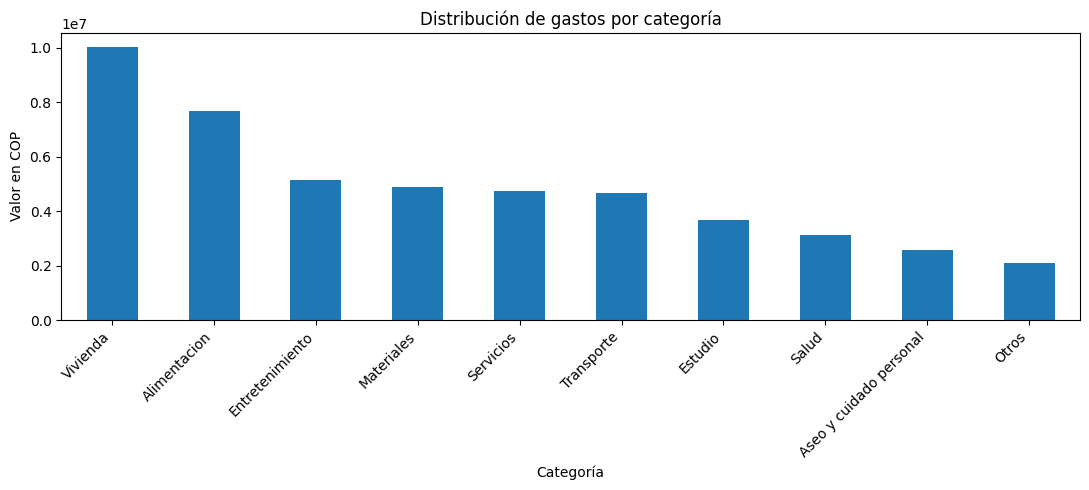


MENÚ DE ANÁLISIS
1. Resumen general e indicadores
2. Gastos por categoría
3. Evolución mensual
4. Comportamiento de gastos
5. Ver todos los resultados
6. Regresar al menú principal
Selecciona un análisis: 2

GASTOS POR CATEGORÍA
--------------------------------
                                total  cantidad   promedio participacion_pct
categoria                                                                   
Vivienda                 $ 10.043.000        40  $ 251.075            20.67%
Alimentacion              $ 7.671.000       444   $ 17.277            15.79%
Entretenimiento           $ 5.135.500       155   $ 33.132            10.57%
Materiales                $ 4.890.500       124   $ 39.440            10.07%
Servicios                 $ 4.741.500        78   $ 60.788             9.76%
Transporte                $ 4.678.000       433   $ 10.804             9.63%
Estudio                   $ 3.658.500        73   $ 50.116             7.53%
Salud                     $ 3.116.000       

KeyboardInterrupt: Interrupted by user

In [ ]:
# Inicio del programa

print("\nBIENVENIDO(A) A MoniApps")
print("------------------------")
print("1. Crear un usuario nuevo")
print("2. Iniciar sesion")

opcion_inicio = input("Selecciona una opcion: ")

if opcion_inicio == "1":
    registrar_usuario()

    print("\nAhora inicia sesion con el usuario que acabas de crear.")
    usuario_activo = iniciar_sesion()

elif opcion_inicio == "2":
    usuario_activo = iniciar_sesion()

else:
    print("Opcion no valida. Ejecuta esta celda nuevamente.")
    usuario_activo = None

# Abrimos el menu si el inicio de sesion fue exitoso

if usuario_activo is not None:
    menu_principal(usuario_activo)
